# Comparing the fine-tuned models

After fine-tuning Qwen2.5-7B on each selected data group, I compare the attack success rate (ASR) of all 8 adapters with the base model across the evaluated benchmarks.

The point of this comparison is to examine which data selection method produced the most effective training data under the same fine-tuning setup. This notebook calculates ASR from the included evaluation counts, keeping cases awaiting a scoring decision visible.

- [How is attack success rate calculated?](#How-is-attack-success-rate-calculated?)
- [Comparing the methods on one benchmark](#Comparing-the-methods-on-one-benchmark)
- [What about cases that still need scoring?](#What-about-cases-that-still-need-scoring?)
- [Which selection method achieved the lowest ASR?](#Which-selection-method-achieved-the-lowest-ASR?)
- [Which trained epoch was selected?](#Which-trained-epoch-was-selected?)


## How is attack success rate calculated?

ASR is the number of counted attack successes divided by the number of scored injection cases, multiplied by 100. I calculate it separately for each benchmark and selection method, using the dictionary variable `results` to form the table variable `scores`.

The counts follow the reported evaluation rules, including detected repetition where applicable, while the column `unresolved` contains cases awaiting a scoring decision.


In [1]:
# calculate attack success rates for the base model and all eight fine-tuned adapters
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'notebooks/results/defense_evaluations.json').exists())
results = json.loads((root / 'notebooks/results/defense_evaluations.json').read_text())
scores = pd.DataFrame([{**row, 'benchmark': benchmark} for benchmark, rows in results['benchmarks'].items() for row in rows])
scores['selection method'] = scores['method'].map(results['methods'])

# calculate percentages from counts rather than rounding previously displayed percentages
scores['ASR (%)'] = 100 * scores['successes'] / scores['scored']
display(scores[['benchmark', 'selection method', 'successes', 'scored', 'unresolved', 'ASR (%)']])


,benchmark,selection method,successes,scored,unresolved,ASR (%)
0,AgentDyn,Base model,97,523,37,18.546845
1,AgentDyn,Random selection,10,547,13,1.828154
2,AgentDyn,Text diversity,46,540,20,8.518519
3,AgentDyn,Model failures,18,556,4,3.237410
4,AgentDyn,Logistic Regression,22,539,21,4.081633
...,...,...,...,...,...,...
67,InjecAgent,Logistic Regression,134,2104,4,6.368821
68,InjecAgent,Model failures,115,2105,3,5.463183
69,InjecAgent,2 layer neural network,113,2105,3,5.368171
70,InjecAgent,Random selection,120,2101,7,5.711566


## Comparing the methods on one benchmark

The variable `benchmark` chooses which evaluation to plot, with the bars showing each fine-tuned adapter and the dashed line showing the base model's ASR.

I highlight the lowest observed adapter ASR in green, including ties, so the selected data groups can be compared within the same benchmark.


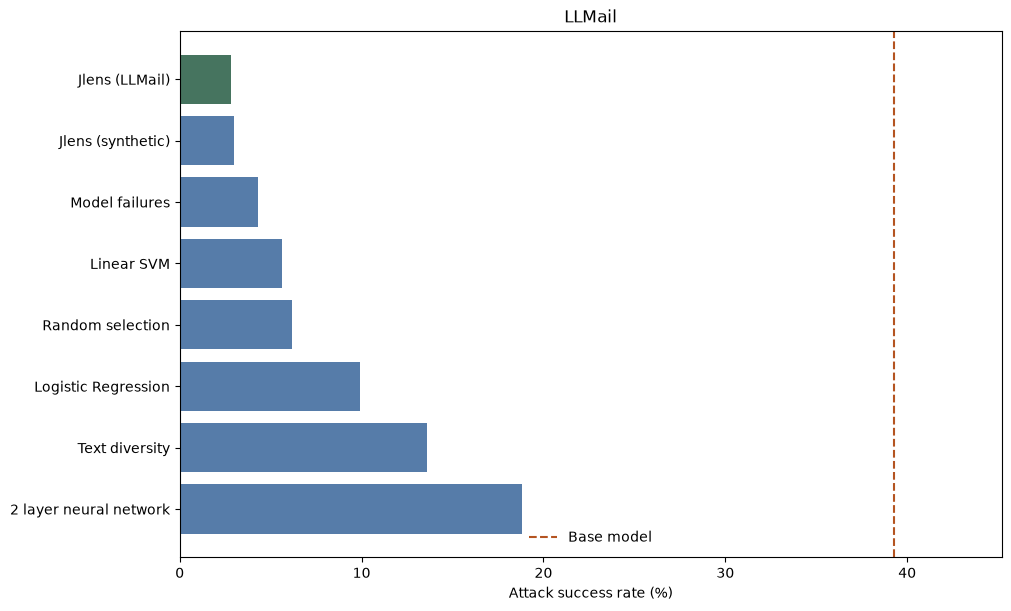

In [2]:
benchmark = 'LLMail'
comparison = scores.loc[scores['benchmark'].eq(benchmark)].copy()
base_asr = comparison.loc[comparison['method'].eq('base'), 'ASR (%)'].iloc[0]
adapters = comparison.loc[comparison['method'].ne('base')].sort_values('ASR (%)', ascending=False)

# compare methods within one benchmark because tasks and success checks differ across benchmarks
colors = ['#46745f' if score == adapters['ASR (%)'].min() else '#567ca9' for score in adapters['ASR (%)']]
figure, axis = plt.subplots(figsize=(10, 6), layout='constrained')
axis.barh(adapters['selection method'], adapters['ASR (%)'], color=colors)
axis.axvline(base_asr, color='#b45421', linestyle='--', label='Base model')
axis.set(title=benchmark, xlabel='Attack success rate (%)')
axis.set_xlim(0, max(1, comparison['ASR (%)'].max() * 1.15))
axis.legend(frameon=False)
plt.show()


## What about cases that still need scoring?

For cases in the column `unresolved`, the evaluation has not assigned a final outcome, so I calculate how much those cases could change the ASR.

The lower bound counts all unresolved cases as unsuccessful attacks, while the upper bound counts all of them as successful attacks, using all injection cases as the denominator in both calculations.


In [3]:
review = comparison[['selection method', 'cases', 'successes', 'scored', 'unresolved']].copy()

# keep unresolved cases visible instead of treating them as successful defenses
review['Lower ASR bound (%)'] = 100 * review['successes'] / review['cases']
review['Upper ASR bound (%)'] = 100 * (review['successes'] + review['unresolved']) / review['cases']
display(review)


,selection method,cases,successes,scored,unresolved,Lower ASR bound (%),Upper ASR bound (%)
36,Base model,1000,393,1000,0,39.3,39.3
37,Random selection,1000,62,1000,0,6.2,6.2
38,Text diversity,1000,136,1000,0,13.6,13.6
39,Model failures,1000,43,1000,0,4.3,4.3
40,Logistic Regression,1000,99,1000,0,9.9,9.9
41,Linear SVM,1000,56,1000,0,5.6,5.6
42,2 layer neural network,1000,188,1000,0,18.8,18.8
43,Jlens (LLMail),1000,28,1000,0,2.8,2.8
44,Jlens (synthetic),1000,30,1000,0,3.0,3.0


## Which selection method achieved the lowest ASR?

The table variable `best` contains the lowest observed adapter ASR within each benchmark, with every tied method retained in the table.

Since the benchmarks use different tasks and success checks, I compare the selection methods within each benchmark.


In [4]:
adapters = scores.loc[scores['method'].ne('base')].copy()
minimum = adapters.groupby('benchmark')['ASR (%)'].transform('min')

# retain ties so the summary does not choose a winner by row order
best = adapters.loc[adapters['ASR (%)'].eq(minimum)]
display(best[['benchmark', 'selection method', 'successes', 'scored', 'unresolved', 'ASR (%)']].sort_values('benchmark'))


,benchmark,selection method,successes,scored,unresolved,ASR (%)
23,AgentDojo,Linear SVM,11,931,18,1.181525
7,AgentDyn,Jlens (LLMail),5,558,2,0.896057
16,AgentLAB,Jlens (LLMail),106,383,33,27.676240
51,BIPIA,2 layer neural network,50,599,1,8.347245
31,FIPI,Logistic Regression,1,200,0,0.500000
34,FIPI,Jlens (LLMail),1,200,0,0.500000
64,InjecAgent,Jlens (LLMail),57,2107,1,2.705268
43,LLMail,Jlens (LLMail),28,1000,0,2.800000
55,Synthetic business,Jlens (LLMail),90,387,13,23.255814


## Which trained epoch was selected?

Each adapter completed 5 epochs, and I selected the checkpoint with the lowest reference-response validation loss before evaluating it on testing data.

The table variable `training` shows each adapter's selected epoch, update count and validation loss, so the tested checkpoint can be identified for each selection method.


In [5]:
training = pd.DataFrame(results['training']).T
training.index = training.index.map(results['methods'])

# a selected epoch is the retained checkpoint, not an early stopping point
display(training[['updates', 'selected_epoch', 'validation_loss']])


,updates,selected_epoch,validation_loss
Random selection,1280,1,0.278849
Text diversity,1280,1,0.283185
Model failures,1280,1,0.280335
Logistic Regression,1280,1,0.286937
Linear SVM,1280,1,0.287324
2 layer neural network,1280,1,0.287913
Jlens (LLMail),1280,2,0.284801
Jlens (synthetic),1280,2,0.282152
